## Which of the 25 countries has sufficent data quaility and temporal coverage to remain in the running for thee modeling dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
analysis_df = pd.read_csv("../data/processed/analysis_df.csv")

print(analysis_df.shape)
analysis_df.head()

(175, 17)


,AreaName,AreaCode,Year,Active mobile-broadband subscriptions,Estimated proportion of households with Internet access at home,Fixed-broadband subscriptions,Internet users (%),Percentage of the population covered by at least an LTE/WiMAX mobile network.,Population,Country Name,Country Code,Electricity_Access,Region,Income group,Mobile_Broadband_per_100,Fixed-broadband_per_100,Coverage_Use_Gap
0,Afghanistan,AFG,2018,6997208.0,7.270304,15999.0,16.799999,7.00,36743039.0,Afghanistan,AFG,93.4,"Middle East, North Africa, Afghanistan & Pakistan",Low income,19.043629,0.043543,-9.799999
1,Afghanistan,AFG,2019,7309797.0,8.438115,19683.0,17.600000,22.00,37856121.0,Afghanistan,AFG,97.7,"Middle East, North Africa, Afghanistan & Pakistan",Low income,19.309419,0.051994,4.400000
2,Afghanistan,AFG,2020,7422550.0,NaN,26570.0,17.048500,26.00,39068979.0,Afghanistan,AFG,97.7,"Middle East, North Africa, Afghanistan & Pakistan",Low income,18.998577,0.068008,8.951500
3,Afghanistan,AFG,2021,7422550.0,24.288903,26570.0,16.514299,26.00,40000412.0,Afghanistan,AFG,97.7,"Middle East, North Africa, Afghanistan & Pakistan",Low income,18.556184,0.066424,9.485701
4,Afghanistan,AFG,2022,22831896.0,27.592028,32313.0,15.866300,33.03,40578842.0,Afghanistan,AFG,85.3,"Middle East, North Africa, Afghanistan & Pakistan",Low income,56.265519,0.079630,17.163700


In [3]:
# Creating table to establish which countries have the most useful data for training the model

model_vars = [
    "Electricity_Access",
    "Internet users (%)",
    "Mobile_Broadband_per_100",
    "Fixed-broadband_per_100",
    "Percentage of the population covered by at least an LTE/WiMAX mobile network."
]

country_data_completeness = (
    analysis_df
    .groupby("Country Name")[model_vars]
    .agg(["count",( "missing", lambda x: x.isna().sum())])
)

country_data_completeness

Electricity_Access         Internet users (%)          \
                              count missing              count missing   
Country Name                                                             
Afghanistan                       7       0                  7       0   
Angola                            7       0                  7       0   
Armenia                           7       0                  7       0   
Barbados                          7       0                  7       0   
Botswana                          7       0                  6       1   
Burkina Faso                      7       0                  7       0   
Cambodia                          7       0                  7       0   
Colombia                          7       0                  7       0   
Ethiopia                          7       0                  7       0   
Honduras                          7       0                  7       0   
India                             7       0                  7       0   
Indonesia                         7       0                  7       0   
Iraq                              7       0                  7       0   
Israel                            7       0                  7       0   
Jamaica                           7       0                  7       0   
Japan                             7       0                  7       0   
Kenya                             7       0                  7       0   
Madagascar                        7       0                  7       0   
Morocco                           7       0                  7       0   
Papua New Guinea                  7       0                  7       0   
Rwanda                            7       0                  7       0   
Spain                             7       0                  7       0   
Uganda                            7       0                  7       0   
Ukraine                           7       0                  7       0   
United States                     7       0                  7       0   

                 Mobile_Broadband_per_100         Fixed-broadband_per_100  \
                                    count missing                   count   
Country Name                                                                
Afghanistan                             7       0                       6   
Angola                                  7       0                       7   
Armenia                                 7       0                       7   
Barbados                                6       1                       5   
Botswana                                7       0                       7   
Burkina Faso                            5       2                       7   
Cambodia                                7       0                       7   
Colombia                                7       0                       7   
Ethiopia                                6       1                       6   
Honduras                                7       0                       7   
India                                   7       0                       7   
Indonesia                               7       0                       7   
Iraq                                    7       0                       7   
Israel                                  7       0                       7   
Jamaica                                 7       0                       7   
Japan                                   6       1                       6   
Kenya                                   7       0                       7   
Madagascar                              7       0                       6   
Morocco                                 7       0                       7   
Papua New Guinea                        5       2                       6   
Rwanda                                  7       0                       7   
Spain                                   7       0                       7   
Uganda             

In [4]:
# Locating the missing values in data

missing_records = (
    analysis_df[analysis_df[model_vars].isna().any(axis=1)]
    [["Country Name", "Year"] + model_vars].sort_values(['Country Name', "Year"]) 
)

missing_records

,Country Name,Year,Electricity_Access,Internet users (%),Mobile_Broadband_per_100,Fixed-broadband_per_100,Percentage of the population covered by at least an LTE/WiMAX mobile network.
6,Afghanistan,2024,87.8,16.094999,60.099082,NaN,37.324101
26,Barbados,2023,100.0,69.675102,NaN,NaN,NaN
27,Barbados,2024,100.0,70.364700,59.936205,NaN,99.000000
33,Botswana,2023,76.0,NaN,111.872300,6.164958,91.000000
37,Burkina Faso,2020,18.5,12.973200,NaN,0.065083,26.920000
40,Burkina Faso,2023,21.7,25.361200,NaN,0.459463,42.390000
56,Ethiopia,2018,44.8,15.886200,NaN,NaN,NaN
111,Japan,2024,100.0,85.541531,NaN,NaN,98.100000
125,Madagascar,2024,42.5,18.677900,28.197129,NaN,34.626694
133,Papua New Guinea,2018,16.6,12.357900,NaN,NaN,NaN


## Modeling Variable Selection

Internet use (%) was selected as the initial target variable because the project seeks to examine how differences in digital infrastructure relate to actual digital adoption. Candidate predictors include electricity access, LTE/WiMAX mobile network coverage, mobile-broadband subscriptions per 100 people, and fixed-broadband subscriptions per 100 people.

Income group and year will be evaluated as additional contextual and temporal predictors. Country name will be retained as an identifier rather than treated as a numeric predictor.

Coverage_Use_Gap will not be used as a predictor of Internet use because the variable is calculated using Internet use itself. Including it would introduce target leakage.
(Coverage_Use_Gap = LTECoverage - InternetUse)

In [5]:
## Creating modeling target variables

target = "Internet users (%)"

predictors = [
    "Electricity_Access",
    "Mobile_Broadband_per_100",
    "Fixed-broadband_per_100",
    "Percentage of the population covered by at least an LTE/WiMAX mobile network."
]

In [6]:
## Creating modeling dataframe with only the countries that have complete data for all model variables

modeling_columns = [
    "Country Name",
    "Year",
    "Income group",
    "Region",
    target
] + predictors 

modeling_df = analysis_df[modeling_columns].copy()

print(modeling_df.shape)
modeling_df.head()


(175, 9)


,Country Name,Year,Income group,Region,Internet users (%),Electricity_Access,Mobile_Broadband_per_100,Fixed-broadband_per_100,Percentage of the population covered by at least an LTE/WiMAX mobile network.
0,Afghanistan,2018,Low income,"Middle East, North Africa, Afghanistan & Pakistan",16.799999,93.4,19.043629,0.043543,7.00
1,Afghanistan,2019,Low income,"Middle East, North Africa, Afghanistan & Pakistan",17.600000,97.7,19.309419,0.051994,22.00
2,Afghanistan,2020,Low income,"Middle East, North Africa, Afghanistan & Pakistan",17.048500,97.7,18.998577,0.068008,26.00
3,Afghanistan,2021,Low income,"Middle East, North Africa, Afghanistan & Pakistan",16.514299,97.7,18.556184,0.066424,26.00
4,Afghanistan,2022,Low income,"Middle East, North Africa, Afghanistan & Pakistan",15.866300,85.3,56.265519,0.079630,33.03


In [7]:
modeling_df.dtypes

Country Name                                                                      object
Year                                                                               int64
Income group                                                                      object
Region                                                                            object
Internet users (%)                                                               float64
Electricity_Access                                                               float64
Mobile_Broadband_per_100                                                         float64
Fixed-broadband_per_100                                                          float64
Percentage of the population covered by at least an LTE/WiMAX mobile network.    float64
dtype: object

## Income Group Selection Rationale

Income group will initially be excluded from the predictor variables and retained as a segmentation variable for model evaluation. This approach allows the initial models to assess the predictive value of digital infrastructure indicators independently of income classification. Model performance will subsequently be compared across income groups to identify potential differences in predictive accuracy. Income group may be introduced as an additional predictor in later model comparisons to determine whether economic classification provides incremental predictive value beyond the infrastructure indicators.

## Region Selection Rationale
Region will be excluded from the initial predictor variables due to the limited number of countries represented in the dataset and potential imbalances in geographic representation. Including region at this stage could introduce additional model complexity and increase the risk of overfitting to country-specific characteristics rather than identifying generalizable relationships. Region will be retained for descriptive analysis and may be reconsidered as a predictor in future modeling iterations if geographic representation and sample size improve.

## Temporal Variable Selection Rationale
Year will be included as an initial predictor to account for temporal patterns in internet adoption between 2018 and 2024. Including this variable may help identify changes in internet use that are not fully captured by the selected infrastructure indicators. However, Year will not be interpreted as a causal explanation for changes in adoption. Its predictive contribution will be evaluated using a chronological validation strategy to determine whether including temporal information improves model performance on later observations.

In [8]:
# Checking for missing values in the modeling dataframe

modeling_df.isna().sum()

Country Name                                                                     0
Year                                                                             0
Income group                                                                     0
Region                                                                           0
Internet users (%)                                                               1
Electricity_Access                                                               0
Mobile_Broadband_per_100                                                         7
Fixed-broadband_per_100                                                          8
Percentage of the population covered by at least an LTE/WiMAX mobile network.    5
dtype: int64

In [9]:
modeling_df[modeling_df["Internet users (%)"].isna()]

,Country Name,Year,Income group,Region,Internet users (%),Electricity_Access,Mobile_Broadband_per_100,Fixed-broadband_per_100,Percentage of the population covered by at least an LTE/WiMAX mobile network.
33,Botswana,2023,Upper middle income,Sub-Saharan Africa,NaN,76.0,111.8723,6.164958,91.0


In [10]:
# Receieved a type error that modeling_df was a list so I had to restore it to a dataframe. 
modeling_df = analysis_df[modeling_columns].copy()

In [11]:
modeling_df[target].isna().sum()

1

In [12]:
# Keeping only the rows with complete data for all model variables

supervised_modeling_df = modeling_df.dropna(subset=[target]).copy()

print('Original observations:', len(modeling_df))
print('Supervised observations:', len(supervised_modeling_df))

Original observations: 175
Supervised observations: 174


In [13]:
# Looking to see how many predictor values are missing in each year for the supervised modeling dataframe

supervised_modeling_df.groupby('Year')[predictors].apply(lambda df: df.isna().sum())

,Electricity_Access,Mobile_Broadband_per_100,Fixed-broadband_per_100,Percentage of the population covered by at least an LTE/WiMAX mobile network.
Year,,,,
2018,0,2,3,4
2019,0,0,0,0
2020,0,1,0,0
2021,0,0,0,0
2022,0,0,0,0
2023,0,3,1,1
2024,0,1,4,0


In [14]:
# Checking to see which countries are missing predictor values in the supervised modeling dataframeS

supervised_modeling_df.loc[supervised_modeling_df[predictors].isna().any(axis=1), ['Country Name', 'Year'] + predictors].sort_values(['Country Name', 'Year'])

,Country Name,Year,Electricity_Access,Mobile_Broadband_per_100,Fixed-broadband_per_100,Percentage of the population covered by at least an LTE/WiMAX mobile network.
6,Afghanistan,2024,87.8,60.099082,NaN,37.324101
26,Barbados,2023,100.0,NaN,NaN,NaN
27,Barbados,2024,100.0,59.936205,NaN,99.000000
37,Burkina Faso,2020,18.5,NaN,0.065083,26.920000
40,Burkina Faso,2023,21.7,NaN,0.459463,42.390000
56,Ethiopia,2018,44.8,NaN,NaN,NaN
111,Japan,2024,100.0,NaN,NaN,98.100000
125,Madagascar,2024,42.5,28.197129,NaN,34.626694
133,Papua New Guinea,2018,16.6,NaN,NaN,NaN
138,Papua New Guinea,2023,20.5,NaN,0.228112,70.000000


In [15]:
# Identifying country-year observation with missing predictors

missing_predictors_rows = supervised_modeling_df.loc[
    supervised_modeling_df[predictors].isna().any(axis=1),
    ["Country Name", "Year"] + predictors
].sort_values(["Country Name", "Year"])

display(missing_predictors_rows)

print("Affected observations:", len(missing_predictors_rows))

,Country Name,Year,Electricity_Access,Mobile_Broadband_per_100,Fixed-broadband_per_100,Percentage of the population covered by at least an LTE/WiMAX mobile network.
6,Afghanistan,2024,87.8,60.099082,NaN,37.324101
26,Barbados,2023,100.0,NaN,NaN,NaN
27,Barbados,2024,100.0,59.936205,NaN,99.000000
37,Burkina Faso,2020,18.5,NaN,0.065083,26.920000
40,Burkina Faso,2023,21.7,NaN,0.459463,42.390000
56,Ethiopia,2018,44.8,NaN,NaN,NaN
111,Japan,2024,100.0,NaN,NaN,98.100000
125,Madagascar,2024,42.5,28.197129,NaN,34.626694
133,Papua New Guinea,2018,16.6,NaN,NaN,NaN
138,Papua New Guinea,2023,20.5,NaN,0.228112,70.000000


Affected observations: 12


In [16]:
#Checking to see whether any country - year observation has more than once

duplicate_observations = supervised_modeling_df.duplicated(subset=["Country Name", "Year"])

print("Number of duplicate observations:", duplicate_observations.sum())

Number of duplicate observations: 0


## Outiler Detection and Data Consistency

In [17]:
# Summary stats for predictor variables 

supervised_modeling_df[predictors].describe().T

,count,mean,std,min,25%,50%,75%,max
Electricity_Access,174.0,79.827011,27.145155,14.400000,55.325000,97.700000,100.000000,100.000000
Mobile_Broadband_per_100,167.0,71.615947,43.868452,10.771141,40.921621,61.202803,98.406022,249.097569
Fixed-broadband_per_100,166.0,11.047028,13.043160,0.043543,0.387755,4.347093,17.229546,45.438732
Percentage of the population covered by at least an LTE/WiMAX mobile network.,169.0,77.745212,29.744769,0.000000,65.000000,95.000000,99.000000,100.000000


In [18]:
# Identify minimum and maximum abservaton for each predictor

for col in predictors:
    max_idx = supervised_modeling_df[col].idxmax()
    min_idx = supervised_modeling_df[col].idxmin()

    print("Predictor:", col)
    display (
        supervised_modeling_df.loc[[min_idx, max_idx], ["Country Name", "Year", col]]
    )

Predictor: Electricity_Access


,Country Name,Year,Electricity_Access
35,Burkina Faso,2018,14.4
15,Armenia,2019,100.0


Predictor: Mobile_Broadband_per_100


,Country Name,Year,Mobile_Broadband_per_100
134,Papua New Guinea,2019,10.771141
110,Japan,2023,249.097569


Predictor: Fixed-broadband_per_100


,Country Name,Year,Fixed-broadband_per_100
0,Afghanistan,2018,0.043543
23,Barbados,2020,45.438732


Predictor: Percentage of the population covered by at least an LTE/WiMAX mobile network.


,Country Name,Year,Percentage of the population covered by at least an LTE/WiMAX mobile network.
35,Burkina Faso,2018,0.0
16,Armenia,2020,100.0


In [19]:
# Identify potential outliers using the IQR (Interquartile Range) method

for col in predictors:

    Q1 = supervised_modeling_df[col].quantile(0.25)
    Q3 = supervised_modeling_df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = supervised_modeling_df[
        (supervised_modeling_df[col] < lower_bound) |
        (supervised_modeling_df[col] > upper_bound)
    ]

    print(f"\n{col}")
    print(f"Lower bound: {lower_bound:.2f}")
    print(f"Upper bound: {upper_bound:.2f}")
    print(f"Potential outliers: {len(outliers)}")


Electricity_Access
Lower bound: -11.69
Upper bound: 167.01
Potential outliers: 0

Mobile_Broadband_per_100
Lower bound: -45.30
Upper bound: 184.63
Potential outliers: 4

Fixed-broadband_per_100
Lower bound: -24.87
Upper bound: 42.49
Potential outliers: 1

Percentage of the population covered by at least an LTE/WiMAX mobile network.
Lower bound: 14.00
Upper bound: 150.00
Potential outliers: 8


In [20]:
# Collect all observations flagged by the IQR method

outlier_results = []

for col in predictors:
    Q1 = supervised_modeling_df[col].quantile(0.25)
    Q3 = supervised_modeling_df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    flagged = supervised_modeling_df.loc[
        (supervised_modeling_df[col] < lower) |
        (supervised_modeling_df[col] > upper),
        ["Country Name", "Year", col]
    ].copy()

    flagged["Predictor"] = col
    flagged["Value"] = flagged[col]

    outlier_results.append(
        flagged[["Country Name", "Year", "Predictor", "Value"]]
    )

outlier_summary = pd.concat(outlier_results, ignore_index=True)

display(outlier_summary)

,Country Name,Year,Predictor,Value
0,Japan,2022,Mobile_Broadband_per_100,232.431992
1,Japan,2023,Mobile_Broadband_per_100,249.097569
2,United States,2023,Mobile_Broadband_per_100,184.682637
3,United States,2024,Mobile_Broadband_per_100,196.707219
4,Barbados,2020,Fixed-broadband_per_100,45.438732
5,Afghanistan,2018,Percentage of the population covered by at lea...,7.000000
6,Angola,2018,Percentage of the population covered by at lea...,8.000000
7,Burkina Faso,2018,Percentage of the population covered by at lea...,0.000000
8,Ethiopia,2019,Percentage of the population covered by at lea...,7.000000
9,Ethiopia,2020,Percentage of the population covered by at lea...,7.000000


## Chronological Train, Validation and Test split

In [21]:
# Splitting the supervised dataset chronologically

train_df = supervised_modeling_df[supervised_modeling_df["Year"] <= 2022].copy()

val_df = supervised_modeling_df[supervised_modeling_df["Year"] == 2023].copy()

test_df = supervised_modeling_df[supervised_modeling_df["Year"] == 2024].copy()

print("Training set:", len(train_df))
print("Validation set:", len(val_df))
print("Test set:", len(test_df))

Training set: 125
Validation set: 24
Test set: 25


### Feature and Target Separtion

In [22]:
# Defining the features for initial modeling 

features = predictors + ["Year"]

# Training Data
x_train = train_df[features].copy()
y_train = train_df[target].copy()

# Validation Data
x_val = val_df[features].copy()
y_val = val_df[target].copy()

# Test Data
x_test = test_df[features].copy()
y_test = test_df[target].copy()

print("Training features shape:", x_train.shape)
print("Training target shape:", y_train.shape)

print("Validation features shape:", x_val.shape)
print("Validation target shape:", y_val.shape)

print("Test features shape:", x_test.shape)
print("Test target shape:", y_test.shape)

Training features shape: (125, 5)
Training target shape: (125,)
Validation features shape: (24, 5)
Validation target shape: (24,)
Test features shape: (25, 5)
Test target shape: (25,)


### Missing Predictor Imputation

In [23]:
from sklearn.impute import SimpleImputer

# Creating median imputer for missing values in the predictor variables

imputer = SimpleImputer(strategy="median")

In [24]:
imputer.fit(x_train)

# Displaying the median learned for each predictor variable
pd.Series(
    imputer.statistics_,
    index=x_train.columns, 
    name="Training Median"
)

Electricity_Access                                                                 97.700000
Mobile_Broadband_per_100                                                           58.269326
Fixed-broadband_per_100                                                             4.012889
Percentage of the population covered by at least an LTE/WiMAX mobile network.      94.000000
Year                                                                             2020.000000
Name: Training Median, dtype: float64

### Preprocessing Pipeline of Impuatation & Scaling

In [25]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge

# Creating a reusable pipeline for preprocessing and modeling
processing_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [26]:
# Learn preprocessing parameters form training data
x_trained_processed = processing_pipeline.fit_transform(x_train)

# Applying learned parameters to validation and test data
x_val_processed = processing_pipeline.transform(x_val)

print("Processed training shape:", x_trained_processed.shape)
print("Processed validation shape:", x_val_processed.shape)

print("Training missing values:", pd.isna(x_trained_processed).sum())
print("Validation missing values:", pd.isna(x_val_processed).sum())

Processed training shape: (125, 5)
Processed validation shape: (24, 5)
Training missing values: 0
Validation missing values: 0


## Model Development and Baseline Evaluation

In [27]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
import numpy as np

# Creating a baseline model using the DummyRegressor that always predicts the mean
baseline_model = DummyRegressor(strategy="mean")

# Train using the training data
baseline_model.fit(x_train, y_train)

# Predict using the validation data
baseline_predictions = baseline_model.predict(x_val)

# Evaluate the baseline model
baseline_mae = mean_absolute_error(y_val, baseline_predictions)
baseline_rmse = np.sqrt(mean_squared_error(y_val, baseline_predictions))
baseline_r2 = r2_score(y_val, baseline_predictions)

print("Baseline MAE:", baseline_mae)
print("Baseline RMSE:", baseline_rmse)
print("Baseline R2:", baseline_r2)

Baseline MAE: 28.16286532334024
Baseline RMSE: 29.995608540868442
Baseline R2: -0.05978936527886902


## Linear Regression Model

In [28]:
# Creating a Multiple Linear Regression Pipeline

linear_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

# Train on the 2018-2022 observations
linear_pipeline.fit(x_train, y_train)

#Predict internet adoption for 2023
linear_predictions = linear_pipeline.predict(x_val)

# Evaluate validation performance
linear_mae = mean_absolute_error(y_val, linear_predictions)
linear_rmse = np.sqrt(mean_squared_error(y_val, linear_predictions))
linear_r2 = r2_score(y_val, linear_predictions)

print("Linear MAE:", linear_mae)
print("Linear RMSE:", linear_rmse)
print("Linear R2:", linear_r2)

Linear MAE: 9.509251810464505
Linear RMSE: 12.481316256799985
Linear R2: 0.8165046859316909


## Ridge Regression

In [29]:
# Creating Ridge Regression Pipeline

ridge_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", Ridge(alpha=1.0))
])

# Train on the 2018-2022 observations
ridge_pipeline.fit(x_train, y_train)

# Predict internet adoption for 2023
ridge_predictions = ridge_pipeline.predict(x_val)

# Evaluate validation performance
ridge_mae = mean_absolute_error(y_val, ridge_predictions)
ridge_rmse = np.sqrt(mean_squared_error(y_val, ridge_predictions))
ridge_r2 = r2_score(y_val, ridge_predictions)

print("Ridge MAE:", ridge_mae)
print("Ridge RMSE:", ridge_rmse)
print("Ridge R2:", ridge_r2)

Ridge MAE: 9.530943676152146
Ridge RMSE: 12.492927239711216
Ridge R2: 0.8161631270913252


## Random Forest Regression Model


In [30]:
from sklearn.ensemble import RandomForestRegressor

# Creating Random Forest Regression Pipeline
rf_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),  
    ("model", RandomForestRegressor(n_estimators=100, random_state=42))
])

# Train on the 2018-2022 observations
rf_pipeline.fit(x_train, y_train)

# Predict internet adoption for 2023
rf_predictions = rf_pipeline.predict(x_val)

# Evaluate validation performance
rf_mae = mean_absolute_error(y_val, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_val, rf_predictions))
rf_r2 = r2_score(y_val, rf_predictions)

print("Random Forest MAE:", rf_mae)
print("Random Forest RMSE:", rf_rmse)
print("Random Forest R2:", rf_r2)

Random Forest MAE: 5.247643605421239
Random Forest RMSE: 7.26408350741011
Random Forest R2: 0.9378464614484215


## Initial Model Comparison

In [31]:
# Compare initial results performance metrics for the baseline, linear regression, ridge regression, and random forest models

model_comparison = pd.DataFrame({
    "Model":[
        "Baseline",
        "Multiple Linear Regression",
        "Ridge Regression",
        "Random Forest"],

    "MAE":[
        baseline_mae,
        linear_mae,
        ridge_mae,
        rf_mae
    ],
    "RMSE":[
        baseline_rmse,
        linear_rmse,
        ridge_rmse,
        rf_rmse
    ],
    "R2":[
        baseline_r2,
        linear_r2,
        ridge_r2,
        rf_r2
    ]
})

model_comparison.sort_values("MAE").round(2)

,Model,MAE,RMSE,R2
3,Random Forest,5.25,7.26,0.94
1,Multiple Linear Regression,9.51,12.48,0.82
2,Ridge Regression,9.53,12.49,0.82
0,Baseline,28.16,30.00,-0.06


## Fine Tuning Random Forest Hyperparameters 

In [32]:
from sklearn.model_selection import ParameterGrid

# Controled small parameter search

rf_param_grid = {
    'n_estimators': [50, 100, 200], 
    'max_depth': [3, 5, 7],
    'min_samples_leaf':[1, 3, 5]
    }

rf_tuning_results = []

for params in ParameterGrid(rf_param_grid):

    rf_tuning_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),  
        ("model", RandomForestRegressor(**params, random_state=42,n_jobs=-1))
    ])

    rf_tuning_pipeline.fit(x_train, y_train)
    rf_predictions = rf_tuning_pipeline.predict(x_val)

    rf_tuning_results.append({
        **params,
        "MAE": mean_absolute_error(y_val, rf_predictions),
        "RMSE": np.sqrt(mean_squared_error(y_val, rf_predictions)),
        "R2": r2_score(y_val, rf_predictions)
    })
rf_tuning_results_df = pd.DataFrame(rf_tuning_results)

display(rf_tuning_results_df.sort_values("MAE").round(2))


,max_depth,min_samples_leaf,n_estimators,MAE,RMSE,R2
18,7,1,50,5.15,6.97,0.94
19,7,1,100,5.21,7.13,0.94
20,7,1,200,5.35,7.24,0.94
10,5,1,100,5.67,7.71,0.93
9,5,1,50,5.70,7.62,0.93
11,5,1,200,5.84,7.85,0.93
21,7,3,50,6.22,8.27,0.92
22,7,3,100,6.30,8.34,0.92
23,7,3,200,6.34,8.43,0.92
12,5,3,50,6.37,8.36,0.92


## Ridge Regession Hyperparameter Tuning

In [33]:
# Testing different regularization strengths for Ridge Regression

ridge_alphas = [0.01, 0.1, 1, 10, 100]

ridge_tuning_results = []

for alpha in ridge_alphas:
    ridge_tuning_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=alpha))
    ])

    # Train on the 2018-2022 observations
    ridge_tuning_pipeline.fit(x_train, y_train)

    # Predict internet adoption for 2023
    ridge_predictions = ridge_tuning_pipeline.predict(x_val)

    # storing the metrics
    ridge_tuning_results.append({
        "alpha": alpha,
        "MAE": mean_absolute_error(y_val, ridge_predictions),
        "RMSE": np.sqrt(mean_squared_error(y_val, ridge_predictions)),
        "R2": r2_score(y_val, ridge_predictions)
    })

ridge_tuning_df = pd.DataFrame(ridge_tuning_results)

display(ridge_tuning_df.sort_values("MAE").round(2))

,alpha,MAE,RMSE,R2
0,0.01,9.51,12.48,0.82
1,0.10,9.51,12.48,0.82
2,1.00,9.53,12.49,0.82
3,10.00,9.75,12.60,0.81
4,100.00,11.60,14.06,0.77


In [34]:
# Creating a new feature interaction between electricity and LTE coverage

lte_col = (
    "Percentage of the population covered by at least an LTE/WiMAX mobile network."
)

def add_infrastructure_interaction(df):
    df = df.copy()
    
    df["Electricity_LTE_Interaction"] = df["Electricity_Access"] * df[lte_col] / 100
    
    return df

x_train_fe = add_infrastructure_interaction(x_train)
x_val_fe = add_infrastructure_interaction(x_val)

print("Training features shape:", x_train.shape)
print("Engineered features shape:", x_train_fe.shape)

display(x_train_fe.head())

Training features shape: (125, 5)
Engineered features shape: (125, 6)


,Electricity_Access,Mobile_Broadband_per_100,Fixed-broadband_per_100,Percentage of the population covered by at least an LTE/WiMAX mobile network.,Year,Electricity_LTE_Interaction
0,93.4,19.043629,0.043543,7.00,2018,6.53800
1,97.7,19.309419,0.051994,22.00,2019,21.49400
2,97.7,18.998577,0.068008,26.00,2020,25.40200
3,97.7,18.556184,0.066424,26.00,2021,25.40200
4,85.3,56.265519,0.079630,33.03,2022,28.17459


## Feature Engineering Performance Comparison

In [35]:
# Train multiple Linear Regression with the new feature

linear_pipeline_fe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

linear_pipeline_fe.fit(x_train_fe, y_train)

# Predict internet adoption for 2023
linear_predictions_fe = linear_pipeline_fe.predict(x_val_fe)

# Evaluate validation performance
linear_mae_fe = mean_absolute_error(y_val, linear_predictions_fe)
linear_rmse_fe = np.sqrt(mean_squared_error(y_val, linear_predictions_fe))
linear_r2_fe = r2_score(y_val, linear_predictions_fe)

# Compare the original linear regression model with the new feature engineered model
feature_engineering_comparison = pd.DataFrame({
    "Model": ["Original", "Feature Engineered"],
    "MAE": [linear_mae, linear_mae_fe],
    "RMSE": [linear_rmse, linear_rmse_fe],
    "R²": [linear_r2, linear_r2_fe]
})

display(feature_engineering_comparison.round(2))

,Model,MAE,RMSE,R²
0,Original,9.51,12.48,0.82
1,Feature Engineered,9.12,12.08,0.83


### Testing engineered featured with the tuned Random Forest

In [36]:
rf_fe_pipeline = Pipeline([
    ("importer", SimpleImputer(strategy="median")),
    ("model", RandomForestRegressor(
        n_estimators=50,
        random_state=42,
        min_samples_leaf=1,
        max_depth=7
    ))
])

rf_fe_pipeline.fit(x_train_fe, y_train)

# Predict internet adoption for 2023
rf_fe_predictions = rf_fe_pipeline.predict(x_val_fe)

# Evaluate validation performance
rf_fe_mae = mean_absolute_error(y_val, rf_fe_predictions)
rf_fe_rmse = np.sqrt(mean_squared_error(y_val, rf_fe_predictions))
rf_fe_r2 = r2_score(y_val, rf_fe_predictions)

rf_fe_comparison = pd.DataFrame({
    "Model": ["Tuned Random Forest", "Feature Engineered Random Forest + Feature Interaction"],
    "MAE": [5.15, # Rounded reference from previous results
             rf_fe_mae],
    "RMSE": [6.97, # Rounded reference from previous results
              rf_fe_rmse],
    "R²": [0.94, # Rounded reference from previous results
            rf_fe_r2]
})

display(rf_fe_comparison.round(2))

,Model,MAE,RMSE,R²
0,Tuned Random Forest,5.15,6.97,0.94
1,Feature Engineered Random Forest + Feature Int...,5.31,7.27,0.94


In [37]:
# Retrieve exact metrics for our best tuned Random Forest
best_rf_row = rf_tuning_results_df.loc[
    rf_tuning_results_df["MAE"].idxmin()
]

rf_fe_comparison = pd.DataFrame({
    "Model": [
        "Tuned Random Forest",
        "Random Forest + Interaction"
    ],
    "MAE": [best_rf_row["MAE"], rf_fe_mae],
    "RMSE": [best_rf_row["RMSE"], rf_fe_rmse],
    "R2": [best_rf_row["R2"], rf_fe_r2]
})

display(rf_fe_comparison.round(3))

,Model,MAE,RMSE,R2
0,Tuned Random Forest,5.153,6.974,0.943
1,Random Forest + Interaction,5.306,7.268,0.938


## Country Level Prediction Error Analysis

In [38]:
# Refit the leading Random Forest Configuration

best_rf_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestRegressor(
        n_estimators=50,
        max_depth=7,
        min_samples_leaf=1,
        random_state=42
    ))
])

best_rf_pipeline.fit(x_train, y_train)

# Generate predictions for 2023
best_rf_predictions = best_rf_pipeline.predict(x_val)

# Create a country-level diagnostics table
country_errors = val_df[
    ["Country Name", "Year", "Income group"]
].copy()

country_errors["Actual"] = y_val
country_errors["Predicted"] = best_rf_predictions

country_errors['Residual'] = (
    country_errors["Actual"] - country_errors['Predicted']
)

country_errors['Absolute_Error'] = country_errors['Residual'].abs()

display(
    country_errors.sort_values(
        "Absolute_Error", ascending=False
    ).round(2)
)

,Country Name,Year,Income group,Actual,Predicted,Residual,Absolute_Error
103,Jamaica,2023,Upper middle income,89.47,69.83,19.64,19.64
26,Barbados,2023,High income,69.68,52.51,17.16,17.16
47,Cambodia,2023,Lower middle income,68.93,58.76,10.16,10.16
89,Iraq,2023,Upper middle income,81.81,73.36,8.45,8.45
75,India,2023,Lower middle income,60.25,52.94,7.31,7.31
12,Angola,2023,Lower middle income,37.89,30.65,7.24,7.24
159,Uganda,2023,Low income,9.29,15.54,-6.25,6.25
117,Kenya,2023,Lower middle income,32.07,37.68,-5.61,5.61
82,Indonesia,2023,Upper middle income,69.21,74.49,-5.28,5.28
138,Papua New Guinea,2023,Lower middle income,18.56,23.58,-5.02,5.02


### Model Performance by Income Group

In [39]:
# Compare prediction errors across income groups

income_group_performance = (
    country_errors
    .groupby("Income group")
    .agg(
        Countries=("Country Name", "nunique"),
        Observations=("Absolute_Error", "count"),
        MAE=("Absolute_Error", "mean"),
        Mean_Residual=("Residual", "mean"),
        Max_Error=("Absolute_Error", "max")
    )
    .sort_values("MAE", ascending=False)
)

display(income_group_performance.round(2))

,Countries,Observations,MAE,Mean_Residual,Max_Error
Income group,,,,,
Upper middle income,6,6,6.64,3.69,19.64
Lower middle income,7,7,5.80,2.30,10.16
High income,5,5,5.53,3.30,17.16
Low income,6,6,2.59,-0.32,6.25


### Actual vs Predicted Internet Adoption

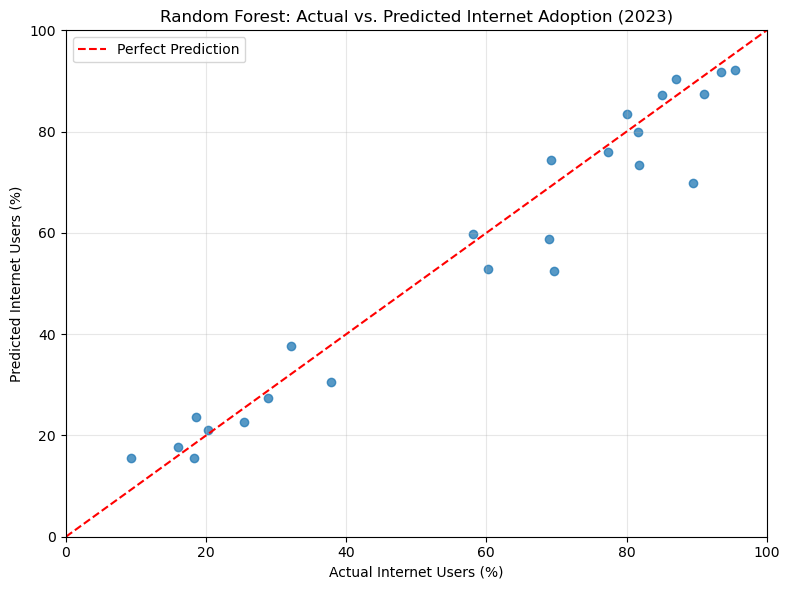

In [40]:
# Visualizing actual vs. predicted internet adoption for 2023

plt.figure(figsize=(8,6))

plt.scatter(
    country_errors["Actual"],
    country_errors['Predicted'],
    alpha=0.75
)

# reference line: perfect predictions
plt.plot(
    [0,100],
    [0,100],
    linestyle="--",
    color="red",
    label="Perfect Prediction"
)

plt.xlabel("Actual Internet Users (%)")
plt.ylabel("Predicted Internet Users (%)")
plt.title("Random Forest: Actual vs. Predicted Internet Adoption (2023)")
plt.xlim(0, 100)
plt.ylim(0, 100)
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Residual Analysis

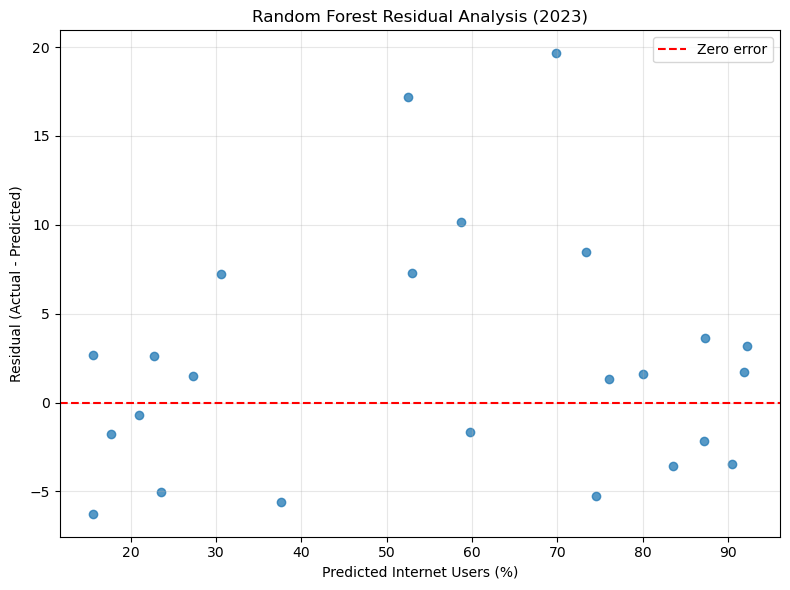

In [41]:
# Plot residuals against predicted internet adoption

plt.figure(figsize=(8, 6))

plt.scatter(
    country_errors["Predicted"],
    country_errors["Residual"],
    alpha=0.75
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    label="Zero error"
)

plt.xlabel("Predicted Internet Users (%)")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Random Forest Residual Analysis (2023)")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Random Forset Feature importance

In [42]:
# Extract feature importance from the trained Random Forest

rf_importance = pd.DataFrame({
    "Feature": x_train.columns,
    "Importance": best_rf_pipeline.named_steps[
        "model"
    ].feature_importances_
})

rf_importance = rf_importance.sort_values(
    "Importance",
    ascending=False
)

display(rf_importance.round(3))

,Feature,Importance
2,Fixed-broadband_per_100,0.719
0,Electricity_Access,0.121
1,Mobile_Broadband_per_100,0.108
3,Percentage of the population covered by at lea...,0.045
4,Year,0.008


### Permutation Feature Importance



In [43]:
from sklearn.inspection import permutation_importance

# Measure importance using the 2023 validation set
permutation_results = permutation_importance(
    best_rf_pipeline,
    x_val,
    y_val,
    scoring="neg_mean_absolute_error",
    n_repeats=30,
    random_state=42,
    n_jobs=-1
)

permutation_df = pd.DataFrame({
    "Feature": x_val.columns,
    "Mean_Importance": permutation_results.importances_mean,
    "Std_Importance": permutation_results.importances_std
})

permutation_df = permutation_df.sort_values(
    "Mean_Importance",
    ascending=False
)

display(permutation_df.round(3))

,Feature,Mean_Importance,Std_Importance
2,Fixed-broadband_per_100,13.410,2.437
1,Mobile_Broadband_per_100,6.114,1.588
0,Electricity_Access,4.473,1.022
3,Percentage of the population covered by at lea...,2.324,0.575
4,Year,0.000,0.000


### Remove Year from the predictor sets

In [44]:
x_train_no_year = x_train.drop(columns=["Year"])
x_val_no_year = x_val.drop(columns=["Year"])

# Train Random Forest without Year
rf_no_year_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestRegressor(
        n_estimators=50,
        max_depth=7,
        min_samples_leaf=1,
        random_state=42
    ))
])

rf_no_year_pipeline.fit(x_train_no_year, y_train)

rf_no_year_predictions = rf_no_year_pipeline.predict(x_val_no_year)

year_comparison = pd.DataFrame({
    "Model": ["With Year", "Without Year"],
    "MAE": [
        best_rf_row["MAE"],
        mean_absolute_error(y_val, rf_no_year_predictions)
    ],
    "RMSE": [
        best_rf_row["RMSE"],
        np.sqrt(mean_squared_error(y_val, rf_no_year_predictions))
    ],
    "R2": [
        best_rf_row["R2"],
        r2_score(y_val, rf_no_year_predictions)
    ]
})

display(year_comparison.round(3))

,Model,MAE,RMSE,R2
0,With Year,5.153,6.974,0.943
1,Without Year,5.413,7.600,0.932


### Final Model Training and Test Evaluation

In [45]:
# Combine training and validation data for final model fitting

x_train_final = pd.concat([x_train, x_val], axis=0)
y_train_final = pd.concat([y_train, y_val], axis=0)

print("Final training features:", x_train_final.shape)
print("Final training targets:", y_train_final.shape)
print("Test features:", x_test.shape)
print("Test targets:", y_test.shape)

Final training features: (149, 5)
Final training targets: (149,)
Test features: (25, 5)
Test targets: (25,)


In [46]:
# Final tuned Random Forest pipeline

final_rf_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestRegressor(
        n_estimators=50,
        max_depth=7,
        min_samples_leaf=1,
        random_state=42
    ))
])

# Fit using 2018–2023 data only
final_rf_pipeline.fit(x_train_final, y_train_final)

print("Final Random Forest training complete!")

Final Random Forest training complete!


In [47]:
# Generate final predictions for 2024

final_rf_predictions = final_rf_pipeline.predict(x_test)

# Calculate test metrics
final_rf_mae = mean_absolute_error(
    y_test, final_rf_predictions
)

final_rf_rmse = np.sqrt(
    mean_squared_error(y_test, final_rf_predictions)
)

final_rf_r2 = r2_score(
    y_test, final_rf_predictions
)

print("2024 Test MAE:", round(final_rf_mae, 3))
print("2024 Test RMSE:", round(final_rf_rmse, 3))
print("2024 Test R²:", round(final_rf_r2, 3))

2024 Test MAE: 7.224
2024 Test RMSE: 10.168
2024 Test R²: 0.872


### Final 2024 Model Comparison

In [48]:
# Evaluate baseline, linear regression, and Ridge on 2024
# using the same 2018–2023 training observations

from sklearn.base import clone

comparison_models = {
    "Baseline": DummyRegressor(strategy="mean"),

    "Multiple Linear Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),

    "Ridge Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=0.01))
    ]),

    "Tuned Random Forest": final_rf_pipeline
}

final_comparison_results = []

for model_name, model in comparison_models.items():

    fitted_model = clone(model)
    fitted_model.fit(x_train_final, y_train_final)

    predictions = fitted_model.predict(x_test)

    final_comparison_results.append({
        "Model": model_name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2": r2_score(y_test, predictions)
    })

final_comparison_df = pd.DataFrame(final_comparison_results)

display(
    final_comparison_df
    .sort_values("MAE")
    .round(3)
)

,Model,MAE,RMSE,R2
3,Tuned Random Forest,7.224,10.168,0.872
1,Multiple Linear Regression,9.718,13.015,0.791
2,Ridge Regression,9.718,13.015,0.791
0,Baseline,27.189,29.376,-0.065


### Final 2024 Country-Level Prediction Error Analysis

In [49]:
# Create country-level diagnostics for the 2024 test set

test_country_errors = test_df[
    ["Country Name", "Year", "Income group"]
].copy()

test_country_errors["Actual"] = y_test
test_country_errors["Predicted"] = final_rf_predictions

# Positive residual = model underestimated adoption
# Negative residual = model overestimated adoption
test_country_errors["Residual"] = (
    test_country_errors["Actual"]
    - test_country_errors["Predicted"]
)

test_country_errors["Absolute_Error"] = (
    test_country_errors["Residual"].abs()
)

display(
    test_country_errors
    .sort_values("Absolute_Error", ascending=False)
    .round(2)
)

,Country Name,Year,Income group,Actual,Predicted,Residual,Absolute_Error
6,Afghanistan,2024,Low income,16.09,44.87,-28.77,28.77
111,Japan,2024,High income,85.54,60.25,25.29,25.29
118,Kenya,2024,Lower middle income,34.98,50.83,-15.85,15.85
160,Uganda,2024,Low income,8.95,23.68,-14.73,14.73
34,Botswana,2024,Upper middle income,57.46,67.43,-9.97,9.97
104,Jamaica,2024,Upper middle income,90.11,80.22,9.89,9.89
13,Angola,2024,Lower middle income,40.70,30.82,9.89,9.89
139,Papua New Guinea,2024,Lower middle income,18.81,28.19,-9.38,9.38
27,Barbados,2024,High income,70.36,61.84,8.53,8.53
90,Iraq,2024,Upper middle income,81.47,75.71,5.77,5.77


### Final 2024 Model Performance by Income Group

In [50]:
# Evaluate final model performance by income group

test_income_performance = (
    test_country_errors
    .groupby("Income group")
    .agg(
        Countries=("Country Name", "nunique"),
        Observations=("Absolute_Error", "count"),
        MAE=("Absolute_Error", "mean"),
        Mean_Residual=("Residual", "mean"),
        Max_Error=("Absolute_Error", "max")
    )
    .sort_values("MAE", ascending=False)
)

display(test_income_performance.round(2))

,Countries,Observations,MAE,Mean_Residual,Max_Error
Income group,,,,,
Low income,6,6,9.07,-7.44,28.77
High income,5,5,8.35,7.31,25.29
Lower middle income,7,7,7.20,-0.01,15.85
Upper middle income,7,7,4.86,1.19,9.97


### Missing Predictor Values and Prediction Error

In [51]:
# Identify missing predictors in the original 2024 test features
missing_predictor_count = x_test.isna().sum(axis=1)

# Add missingness information to our existing diagnostics
missingness_diagnostics = test_country_errors.copy()

missingness_diagnostics["Missing_Predictors"] = (
    missing_predictor_count
)

missingness_diagnostics["Has_Missing_Predictors"] = (
    missingness_diagnostics["Missing_Predictors"] > 0
)

# Compare prediction errors by missing-data status
missingness_summary = (
    missingness_diagnostics
    .groupby("Has_Missing_Predictors")
    .agg(
        Countries=("Country Name", "count"),
        MAE=("Absolute_Error", "mean"),
        Max_Error=("Absolute_Error", "max")
    )
)

display(missingness_summary.round(2))

,Countries,MAE,Max_Error
Has_Missing_Predictors,,,
False,21,5.56,15.85
True,4,15.94,28.77


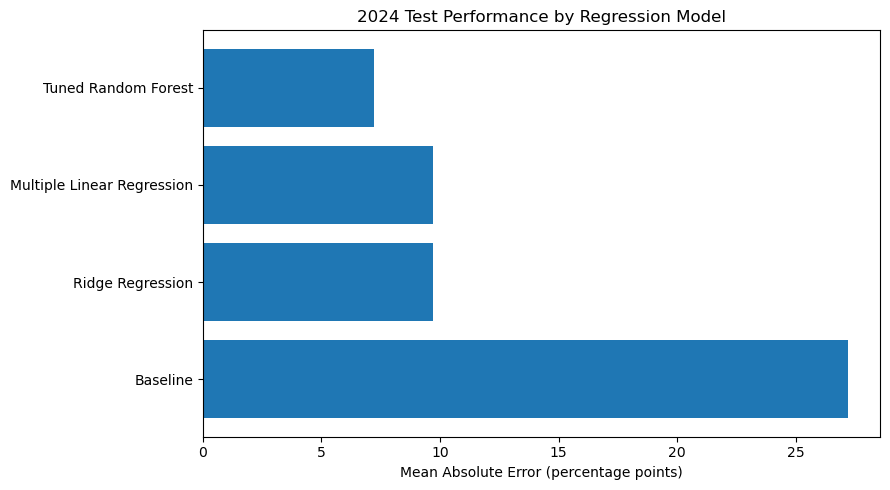

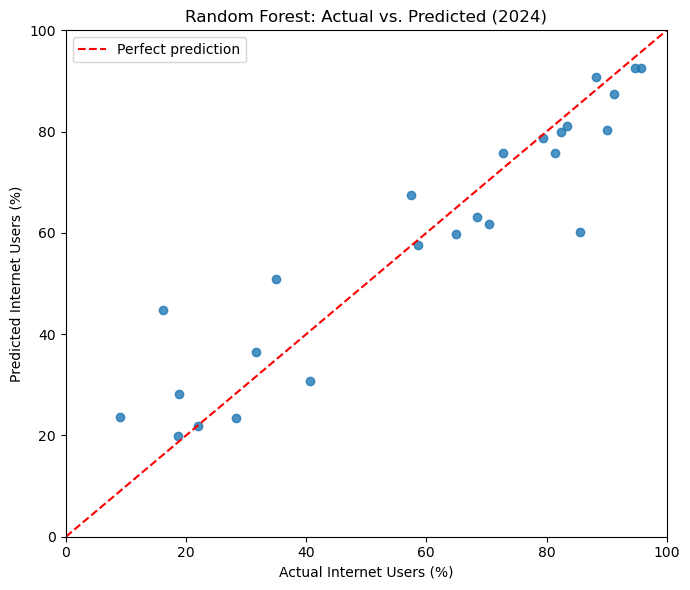

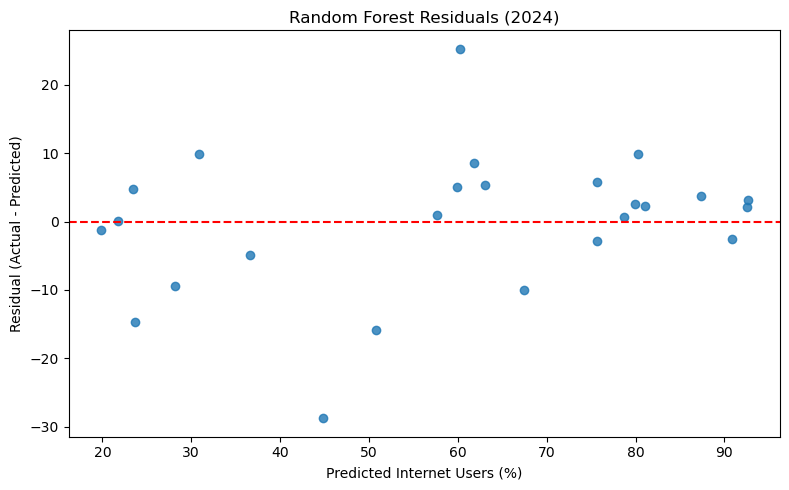

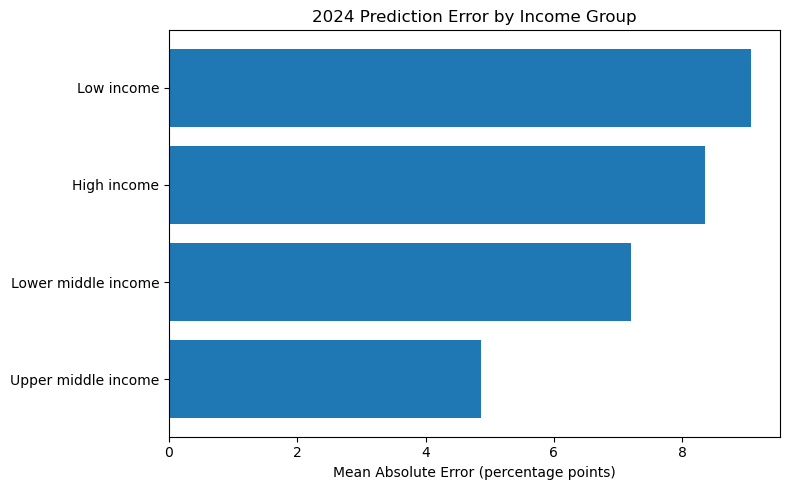

All four figures saved to: C:\Users\arian\OneDrive\Desktop\MoDS\ai-readiness-governance-capstone\reports


In [52]:
from pathlib import Path

# Create reports folder if needed
reports_dir = Path("../reports")
reports_dir.mkdir(parents=True, exist_ok=True)

# Figure 1: Final model comparison
fig, ax = plt.subplots(figsize=(9, 5))

plot_df = final_comparison_df.sort_values("MAE")

ax.barh(plot_df["Model"], plot_df["MAE"])
ax.invert_yaxis()

ax.set_xlabel("Mean Absolute Error (percentage points)")
ax.set_title("2024 Test Performance by Regression Model")

fig.tight_layout()
fig.savefig(reports_dir / "assignment2_model_comparison.png", dpi=300)
plt.show()

# Figure 2: Actual vs. predicted
fig, ax = plt.subplots(figsize=(7, 6))

ax.scatter(
    test_country_errors["Actual"],
    test_country_errors["Predicted"],
    alpha=0.8
)

ax.plot([0, 100], [0, 100], "r--", label="Perfect prediction")

ax.set(
    xlabel="Actual Internet Users (%)",
    ylabel="Predicted Internet Users (%)",
    title="Random Forest: Actual vs. Predicted (2024)",
    xlim=(0, 100),
    ylim=(0, 100)
)

ax.legend()
fig.tight_layout()
fig.savefig(reports_dir / "assignment2_actual_vs_predicted.png", dpi=300)
plt.show()

# Figure 3: Residual analysis
fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(
    test_country_errors["Predicted"],
    test_country_errors["Residual"],
    alpha=0.8
)

ax.axhline(0, color="red", linestyle="--")

ax.set(
    xlabel="Predicted Internet Users (%)",
    ylabel="Residual (Actual - Predicted)",
    title="Random Forest Residuals (2024)"
)

fig.tight_layout()
fig.savefig(reports_dir / "assignment2_residuals.png", dpi=300)
plt.show()

# Figure 4: Income-group performance
fig, ax = plt.subplots(figsize=(8, 5))

income_plot = test_income_performance.sort_values("MAE")

ax.barh(income_plot.index, income_plot["MAE"])

ax.set_xlabel("Mean Absolute Error (percentage points)")
ax.set_title("2024 Prediction Error by Income Group")

fig.tight_layout()
fig.savefig(reports_dir / "assignment2_income_group_mae.png", dpi=300)
plt.show()

print("All four figures saved to:", reports_dir.resolve())

### Export Final Modeling Results and Artifacts

In [53]:
import joblib
from pathlib import Path

# Output directories
reports_dir = Path("../reports")
models_dir = Path("../models")

reports_dir.mkdir(parents=True, exist_ok=True)
models_dir.mkdir(parents=True, exist_ok=True)

# Save evaluation tables
final_comparison_df.to_csv(
    reports_dir / "assignment2_model_comparison.csv",
    index=False
)

test_country_errors.to_csv(
    reports_dir / "assignment2_country_errors.csv",
    index=False
)

test_income_performance.to_csv(
    reports_dir / "assignment2_income_group_performance.csv"
)

missingness_summary.to_csv(
    reports_dir / "assignment2_missingness_summary.csv"
)

# Save fitted Random Forest pipeline
joblib.dump(
    final_rf_pipeline,
    models_dir / "experiment_a_random_forest.joblib"
)

print("All tables and model artifacts exported successfully!")

All tables and model artifacts exported successfully!


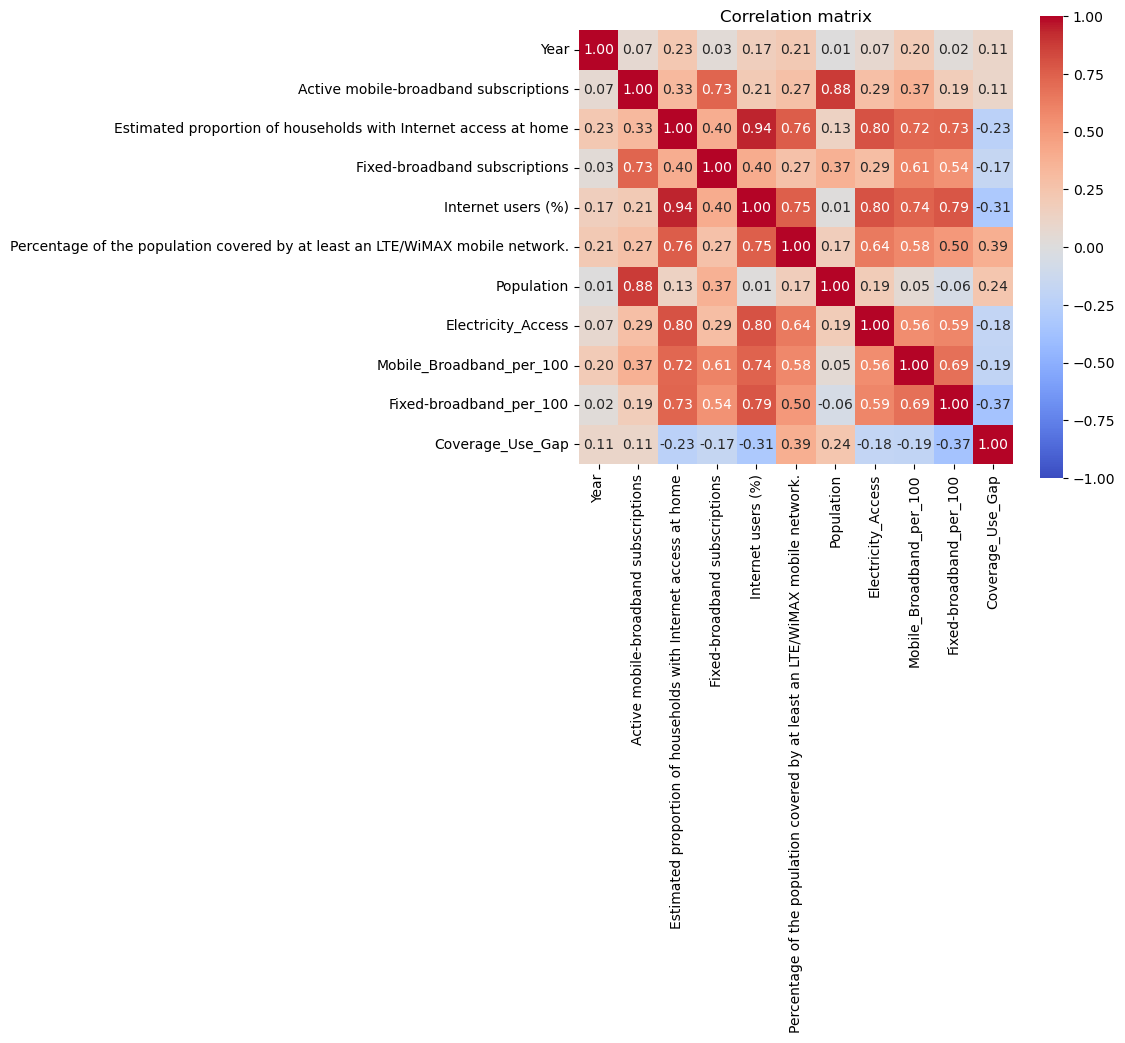

In [57]:
import seaborn as sns

corr = analysis_df.corr(numeric_only=True)


plt.figure(figsize=(7, 6))


sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Correlation matrix")
plt.show()